# Build Forcing Validation - Precipitation
- Tony Grove

In [1]:
%matplotlib ipympl
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
#from gdriver.gdriver import get_credentials, getCSVtoPandas
from buildforcing.datasets import PNNLSnotel
import os

In [2]:
# Run parameters
site = 'Tony Grove RS'
latitude = 41.89
longitude = -111.57
start_date = '20150101'
end_date = '20150201'
buildforcing_version = 'v0.1'
environment = '/home/chriscox/Data/'

### Comparison of NLDAS and SNOTEL

In [3]:
nldas_forcing = xr.open_dataset(os.path.join(environment,'nldas',f'NLDAS_{latitude}_{longitude}_{start_date}_{end_date}.nc'))

<frozen importlib._bootstrap>:488: RuntimeWarning: numpy.ndarray size changed, may indicate binary incompatibility. Expected 16 from C header, got 96 from PyObject


In [7]:
nldas_forcing

<xarray.Dataset> Size: 55kB
Dimensions:    (Date&Time: 768)
Coordinates:
  * Date&Time  (Date&Time) datetime64[ns] 6kB 2015-01-01 ... 2015-02-01T23:00:00
Data variables:
    LWdown     (Date&Time) float64 6kB ...
    PSurf      (Date&Time) float64 6kB ...
    Qair       (Date&Time) float64 6kB ...
    Rainf      (Date&Time) float64 6kB ...
    SWdown     (Date&Time) float64 6kB ...
    Tair       (Date&Time) float64 6kB ...
    Wind_E     (Date&Time) float64 6kB ...
    Wind_N     (Date&Time) float64 6kB ...

In [5]:
snotel = PNNLSnotel(site_name=site, storage_path=os.path.join(environment, 'snotel'))

In [8]:
# Extract the precipitation data from nldas
nldas_precip = nldas_forcing['Rainf'].to_dataframe()

In [9]:
snotel.data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
2009-06-08 00:00:00-06:00,NaN,NaN,NaN,NaN,0.0
2009-06-09 00:00:00-06:00,NaN,NaN,NaN,NaN,0.0
2009-06-10 00:00:00-06:00,12.261111,5.394444,8.255556,NaN,0.0
2009-06-11 00:00:00-06:00,13.405556,5.394444,8.255556,NaN,0.0
2009-06-12 00:00:00-06:00,17.411111,4.822222,10.544444,NaN,0.0


In [11]:
# Localize the precip data to UTC and then change to America/Denver
nldas_precip.index = nldas_precip.index.tz_localize('UTC').tz_convert('America/Denver')

<Axes: xlabel='Date&Time'>

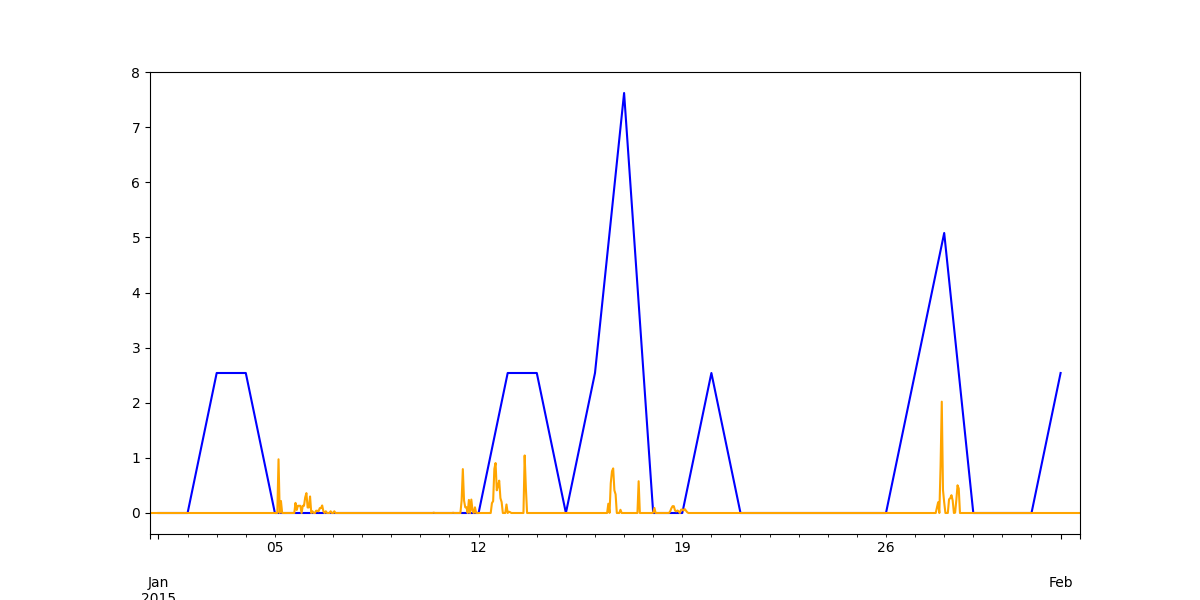

In [13]:
# Plot SNOTEL and NLDAS data
fig, ax = plt.subplots(figsize=(12, 6))
snotel.data.loc[start_date:end_date,'precip_mm'].plot(ax=ax, label='SNOTEL Precipitation', color='blue')
nldas_precip['Rainf'].plot(ax=ax, label='NLDAS Precipitation', color='orange')

### Load datasets

In [ ]:
# Load the forcing dataset
tg_forcing = xr.open_dataset('C:/Users/clmbn/NMT_PhD/data/forcing/tonygrove_20150101_20150201_v0.nc')

In [ ]:
tg_forcing

In [ ]:
# Extract Tair from dataset to a pandas dataframe ignoring the lat/lon dimensions
# and keeping the time dimension
forcing_Tair = tg_forcing['Tair'].isel(latitude=0, longitude=0)
forcing_Tair = forcing_Tair.to_dataframe()

In [ ]:
# Convert temperature from Kelvin to Celsius
forcing_Tair['Tair_C'] = forcing_Tair['Tair'] - 273.15

In [ ]:
# Extract SWdown from dataset to a pandas dataframe ignoring the lat/lon dimensions
# and keeping the time dimension
forcing_SWdown = tg_forcing['SWdown'].isel(latitude=0, longitude=0)
forcing_SWdown = forcing_SWdown.to_dataframe()

### Harmonize timezones
I seem to remember finding a problem with the UTC times in the gamut data. Change forcing to America/Denver to compare.


In [ ]:
forcing_Tair.index = forcing_Tair.index.tz_localize('UTC').tz_convert('America/Denver')
forcing_SWdown.index = forcing_SWdown.index.tz_localize('UTC').tz_convert('America/Denver')

### Load GAMUT

In [ ]:
# Load gdriver credentials
credentials = get_credentials()

# Get the ST110 data
gamut_st110 = getCSVtoPandas('TonyGrove/LR_TG_C_AirTemp_ST110_Avg_SourceID_1_QC_1.csv',credentials,skiprows=56)

# Change index to DateTimeUTC
gamut_st110['DateTime'] = pd.to_datetime(gamut_st110['LocalDateTime'])
gamut_st110 = gamut_st110.set_index('DateTime')

# Convert -9999 to NaN
gamut_st110 = gamut_st110.replace(-9999, np.nan)

In [ ]:
# Extract a subset of the data for the time period of interest
start_date = '2015-01-01 00:00:00'
end_date = '2015-02-01 00:00:00'
gamut_st110_month = gamut_st110.loc[start_date:end_date]

# Localize datetime to america/denver timezone
gamut_st110_month.index = gamut_st110_month.index.tz_localize('America/Denver')

In [ ]:
# Get SW gamut data: SP230
gamut_sp230 = getCSVtoPandas('TonyGrove/LR_TG_C_SWIn_SP230_Avg_SourceID_1_QC_1.csv',credentials,skiprows=55)
gamut_sp230['DateTime'] = pd.to_datetime(gamut_sp230['LocalDateTime'])
gamut_sp230 = gamut_sp230.set_index('DateTime')
gamut_sp230 = gamut_sp230.replace(-9999, np.nan)

In [ ]:
# Extract one month of sp230 data
gamut_sp230_month = gamut_sp230.loc[start_date:end_date]
# Localize datetime to america/denver timezone
gamut_sp230_month.index = gamut_sp230_month.index.tz_localize('America/Denver')

## Comparisons

In [ ]:
# Plot Tair and compare to ST110 data
fig, ax = plt.subplots(figsize=(12, 6))
forcing_Tair['Tair_C'].plot(ax=ax, label='Forcing Tair (C)', color='blue')
gamut_st110_month['AirTemp_ST110_Avg'].plot(ax=ax, label='GAMUT Tair (C)', color='red')

#

In [ ]:
# Plot SWdown and compare to SP230 data
fig, ax = plt.subplots(figsize=(12, 6))
forcing_SWdown['SWdown'].plot(ax=ax, label='Forcing SWdown (W/m2)', color='blue')
gamut_sp230_month['SWIn_SP230_Avg'].plot(ax=ax, label='GAMUT SWdown (W/m2)', color='red')